# 00 — Validación del entorno

## Objetivo pedagógico

Comprobar que el laboratorio ESP-DataScience usa el entorno virtual local antes de leer los Excel experimentales.

Al terminar este cuaderno debe quedar claro:

1. Qué intérprete de Python está ejecutando el notebook.
2. Qué versiones de NumPy, pandas, Matplotlib, SciPy y scikit-learn están importadas.
3. Cómo se distingue un gráfico de práctica de una figura construida con mediciones.

El gráfico final usa números inventados para el ejercicio. Esos valores no describen la bomba ni los ensayos de mapping o surging.

## Intérprete y directorio de trabajo

La celda comprueba que el intérprete pertenece al `.venv` del laboratorio y muestra esas rutas **respecto de la raíz del proyecto**. Así el cuaderno no guarda la carpeta personal de un computador.


In [1]:
import sys
from pathlib import Path


def encontrar_raiz_laboratorio() -> Path:
    actual = Path.cwd().resolve()
    for candidato in [actual, *actual.parents]:
        if (candidato / "notebooks").is_dir() and (candidato / "data" / "raw").is_dir():
            return candidato
    raise FileNotFoundError("No se encontró la raíz del laboratorio.")


raiz = encontrar_raiz_laboratorio()
entorno = Path(sys.prefix).resolve()
trabajo = Path.cwd().resolve()
if entorno.name != ".venv":
    raise RuntimeError("El kernel no está usando el .venv de este laboratorio.")

print("Versión de Python:", sys.version)
print("Entorno relativo a la raíz:", entorno.relative_to(raiz))
print("Directorio de trabajo relativo a la raíz:", trabajo.relative_to(raiz))


Versión de Python: 3.14.7 (main, Aug 10 2026, 00:00:00) [GCC 15.3.1 20260722 (Red Hat 15.3.1-1)]
Entorno relativo a la raíz: .venv
Directorio de trabajo relativo a la raíz: notebooks


## Bibliotecas del laboratorio

Se importan las bibliotecas científicas instaladas en el entorno. scikit-learn se importa como `sklearn`, que es el nombre del módulo.

In [2]:
import matplotlib
import numpy as np
import pandas as pd
import scipy
import sklearn

bibliotecas = {
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}

for nombre, version in bibliotecas.items():
    print(f"{nombre}: {version}")

numpy: 2.5.4
pandas: 3.0.6
matplotlib: 3.11.2
scipy: 1.18.1
scikit-learn: 1.9.1


## Gráfico didáctico de caudal frente a presión

Los seis puntos están escritos a mano en la celda siguiente. Sirven para comprobar que Matplotlib dibuja dentro del notebook.

**Estos valores son ficticios. No provienen de los experimentos de mapping ni de surging, ni de ninguna medición de la investigación.**

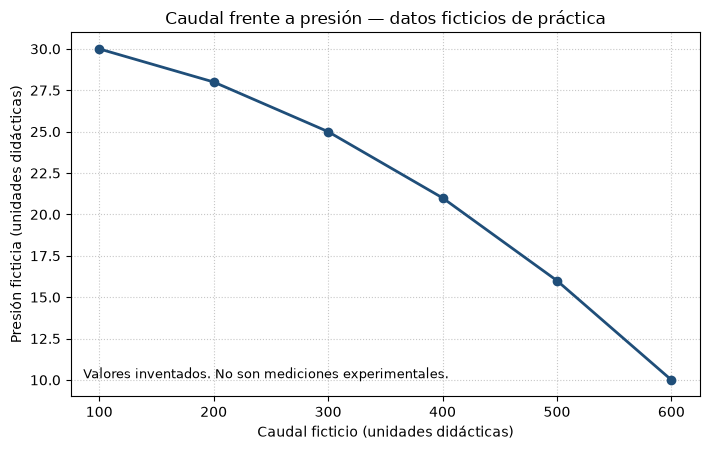

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display

caudal_ficticio = np.array([100, 200, 300, 400, 500, 600], dtype=float)
presion_ficticia = np.array([30, 28, 25, 21, 16, 10], dtype=float)

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.plot(
    caudal_ficticio,
    presion_ficticia,
    marker="o",
    color="#1f4e79",
    linewidth=2,
)
ax.set_title("Caudal frente a presión — datos ficticios de práctica")
ax.set_xlabel("Caudal ficticio (unidades didácticas)")
ax.set_ylabel("Presión ficticia (unidades didácticas)")
ax.grid(True, linestyle=":", alpha=0.7)
ax.text(
    0.02,
    0.05,
    "Valores inventados. No son mediciones experimentales.",
    transform=ax.transAxes,
    fontsize=9,
)
fig.tight_layout()
display(fig)
plt.close(fig)